In [1]:
import mne
import os
import sys
import pandas as pd
from tqdm import tqdm
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import ttest_rel
import itertools

from src.utils import write

ModuleNotFoundError: No module named 'seaborn'

### Configuration

In [19]:
# Paths to data folders
DATA_PATH = "PREPROCESSED_frontal"

# Range settings
FMIN = 4 # in Hz
FMAX = 7 # in Hz
RESOLUTION = 1 # in Hz
OVERLAP = 0.2 # in %

MIN_EPOCHS = 3

# Output and visualization settings
SAVE_DATA = False # If True, save preprocessed epochs to disk as FIF files.
WRITE_INFO = False # If True, print textual progress and summary information.

In [20]:
def split_epochs_by_load_acc(epochs, loads=(2, 3, 4, 5, 6), accs=(-1, 0, 1), by_acc=False, min_epochs=1):
    """
    Split epochs into a nested dictionary by load and accuracy.

    Returns
    -------
    epochs_dict : dict
        Nested dictionary of the form:
            epochs_dict[load][acc] -> mne.Epochs

        If by_acc == False:
            - all accuracies for a given load are combined into a single Epochs
            - the inner key is the string 'all'
              (i.e., epochs_dict[load]['all'])

        If by_acc == True:
            - accuracies are kept separate
            - inner keys are values from `accs` (e.g., -1, 0, 1)
    """
    epochs_dict = {}
    if by_acc:
        possible_acc = accs[:]
    else:
        possible_acc = ["all"]

    for load in loads:
        for acc in possible_acc:
            if acc == "all":
                key = [trigg for trigg in epochs.event_id if trigg.startswith(f"experiment_mask_{load}")]
            else:
                key = [trigg for trigg in epochs.event_id if trigg.startswith(f"experiment_mask_{load}_{acc}")]
            if len(epochs[key]) >= min_epochs:
                if load not in epochs_dict:
                    epochs_dict[load] = {}
                epochs_dict[load][acc] = epochs[key]
    return epochs_dict

def calculate_psd_by_group_per_epoch(epochs_by_load, fmin, fmax, resolution=1, overlap=0):
    first_load_dict = next(iter(epochs_by_load.values()))
    first_ep = next(iter(first_load_dict.values()))
    sfreq = first_ep.info["sfreq"]

    n_fft = int(sfreq / resolution)
    n_overlap = int(overlap * n_fft)

    rows = []

    for load, acc_dict in epochs_by_load.items():
        for acc, ep in acc_dict.items():
            if len(ep) == 0:
                continue

            psd = ep.compute_psd(
                method='welch',
                fmin=fmin,
                fmax=fmax,
                n_fft=n_fft,
                n_overlap=n_overlap,
                verbose=False,
            )
            freqs = psd.freqs              # shape: (n_freqs,)
            psd_data = psd.get_data()      # shape: (n_epochs, n_channels, n_freqs)

            psd_mean_ch = psd_data.mean(axis=1)  # (n_epochs, n_freqs)

            for epoch_idx in range(psd_mean_ch.shape[0]):
                for fi, f in enumerate(freqs):
                    rows.append({
                        "load": load,
                        "acc": acc,
                        "epoch": epoch_idx,
                        "freq": f,
                        "psd": psd_mean_ch[epoch_idx, fi],
                    })

    return pd.DataFrame(rows)

def winsorize_group(x, k=2.5):
    m = x.mean()
    s = x.std(ddof=1)
    low = m - k * s
    high = m + k * s
    return x.clip(lower=low, upper=high)

### Analysis

In [21]:
all_results = []

for file in tqdm(os.listdir(DATA_PATH)):
    part_id = file.split("_")[0]
    write(part_id, WRITE_INFO)
    epochs = mne.read_epochs(os.path.join(DATA_PATH, file), verbose=False)
    epochs_by_load = split_epochs_by_load_acc(epochs, min_epochs=MIN_EPOCHS)
    psd_by_load = calculate_psd_by_group_per_epoch(epochs_by_load, fmin=FMIN, fmax=FMAX, resolution=RESOLUTION, overlap=OVERLAP)

    psd_by_load['participant'] = part_id
    all_results.append(psd_by_load)
    sys.stdout.flush() # for correct order of printed text when using tqdm

# --- Concatenate results ---
df_all = pd.concat(all_results, ignore_index=True)

# calculate log
df_all["log_psd"] = np.log10(df_all["psd"])

# cut to 2.5 SD
group_cols = ["participant", "load"]
df_all["log_psd"] = (df_all.groupby(group_cols)["log_psd"].transform(winsorize_group))

100%|██████████| 147/147 [00:30<00:00,  4.79it/s]


### Outliers
Find and remove epochs outliers

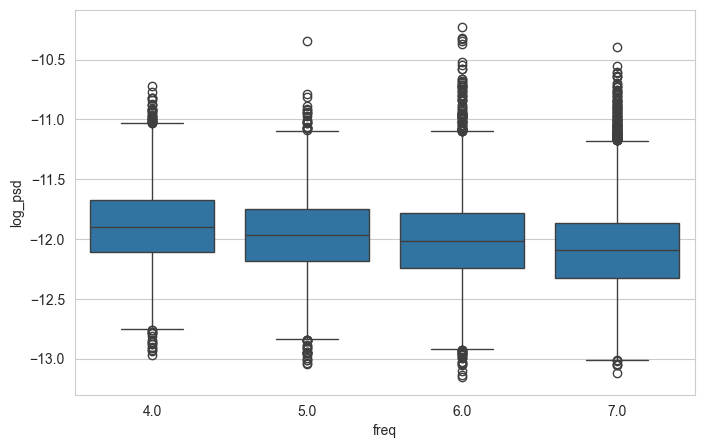

In [22]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_all, x="freq", y="log_psd")
plt.show()

In [23]:
# Find outlier epochs
epoch_power = (
    df_all
    .groupby(["participant", "load", "acc", "epoch"], as_index=False)["log_psd"]
    .mean()
    .rename(columns={"log_psd": "epoch_log_power"})
)
epoch_power["z_within_part"] = (
    epoch_power
    .groupby("participant")["epoch_log_power"]
    .transform(lambda x: (x - x.mean()) / x.std(ddof=0))
)
epoch_outliers = epoch_power[epoch_power["z_within_part"].abs() > 3]

to_drop = epoch_outliers[["participant", "load", "acc", "epoch"]]

# remove outlier epochs
df_all_clean = df_all.merge(
    to_drop.assign(to_remove=True),
    on=["participant", "load", "acc", "epoch"],
    how="left"
)
df_all_clean = df_all_clean[df_all_clean["to_remove"].isna()].drop(columns=["to_remove"])

print("Outlier epochs:")
to_drop

Outlier epochs:


,participant,load,acc,epoch
1803,DW2201,4,all,9
2359,GZ1103,3,all,8
2771,JB1302,5,all,4
2906,JD0609,2,all,9
3174,JF1909,5,all,5
4193,KG2910,3,all,4
4251,KK2701,3,all,9
4369,KM0202,4,all,6
5056,MB2201,2,all,11
5225,ME2605,4,all,5


### Normalization

In [24]:
# Normalization in participant
df_all_clean["psd_z_within"] = (
    df_all_clean
    .groupby("participant")["log_psd"]
    .transform(lambda x: (x - x.mean()) / x.std(ddof=0))
)

# Normalization between participants
df_all_clean["psd_z_between"] = (
    df_all_clean
    .groupby(["freq", "load"])["psd_z_within"]
    .transform(lambda x: (x - x.mean()) / x.std(ddof=0))
)

scores = (
    df_all_clean
    .groupby("participant")["psd_z_between"]
    .apply(lambda x: x.abs().quantile(0.95))  # p95 z |z_between|
    .to_frame(name="score_p95")
)

# z-score on score_p95
scores["score_p95_z"] = (
    (scores["score_p95"] - scores["score_p95"].mean()) /
    scores["score_p95"].std(ddof=0)
)

# Remove outliers with score_p95_z > 2.0
BAD_Z = 2
bad_parts = scores.index[scores["score_p95_z"] > BAD_Z].tolist()

print("Outliers:", bad_parts)
df_final = df_all_clean[~df_all_clean["participant"].isin(bad_parts)].copy()

Outliers: ['DB1009', 'JJ1802', 'KD2912', 'WB0308']


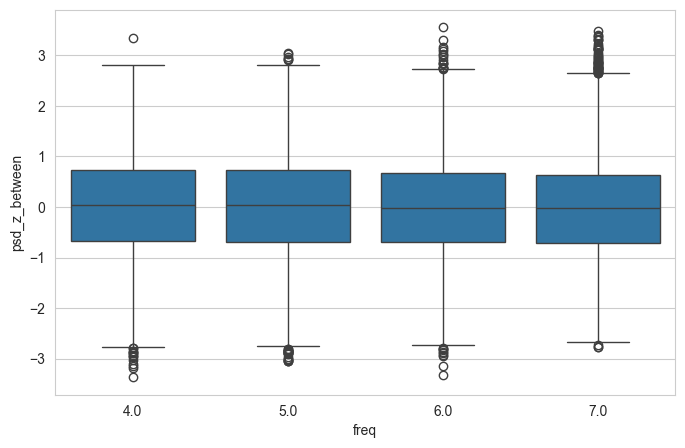

In [25]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_final, x="freq", y="psd_z_between")
plt.show()

### Load 2-3 vs 5-6

In [26]:
sub = df_final[df_final["load"].isin([2, 3, 4, 5, 6])]

g = (
    sub
    .groupby(["participant", "freq", "load"])["psd_z_within"]
    .mean()
    .unstack("load")
)

g["g23"] = g[[2, 3]].mean(axis=1)
g["g56"] = g[[5, 6]].mean(axis=1)

rows = []

for f, d in g.groupby("freq"):
    d = d.dropna(subset=["g23", "g56"])
    t, p = ttest_rel(d["g23"], d["g56"])
    rows.append({"freq": f, "t": t, "p": p, "n": len(d)})

stats_df = pd.DataFrame(rows).set_index("freq").sort_index()
stats_df

,t,p,n
freq,,,
4.0,3.002196,0.003168,143
5.0,1.949986,0.053148,143
6.0,2.205624,0.029018,143
7.0,2.180633,0.030857,143


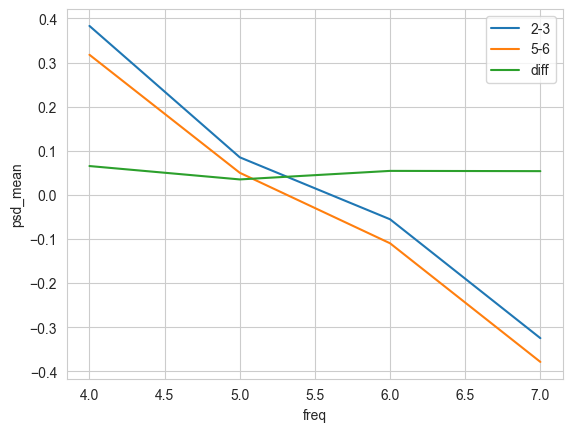

In [27]:
# Epochs mean
df_mean = (
    df_final
    .groupby(["load", "acc", "freq"], as_index=False)["psd_z_within"]
    .mean()
    .rename(columns={"psd_z_within": "psd_mean"})
)

pivot = df_mean.pivot(index="freq", columns="load", values="psd_mean")

plot_df = pd.DataFrame({
    "2-3": pivot[[2, 3]].mean(axis=1),
    "5-6": pivot[[5, 6]].mean(axis=1),
})
plot_df["diff"] = plot_df["2-3"] - plot_df["5-6"]
plot_df.plot()
plt.xlabel("freq")
plt.ylabel("psd_mean")
plt.show()

In [28]:
g_part = (
    g[["g23", "g56"]]
    .reset_index()              # participant, freq, g23, g56
    .groupby("participant")[["g23", "g56"]]
    .mean()                     # freq mean
)

g_part = g_part.dropna(subset=["g23", "g56"])
t_all, p_all = ttest_rel(g_part["g23"], g_part["g56"])

n_all = len(g_part)
f"t: {t_all}, p: {p_all}, d: {t_all/np.sqrt(n_all)}, n: {n_all}"

't: 3.172895657709742, p: 0.0018502895754554816, d: 0.26533086423459645, n: 143'

### Load differences

<Axes: xlabel='freq'>

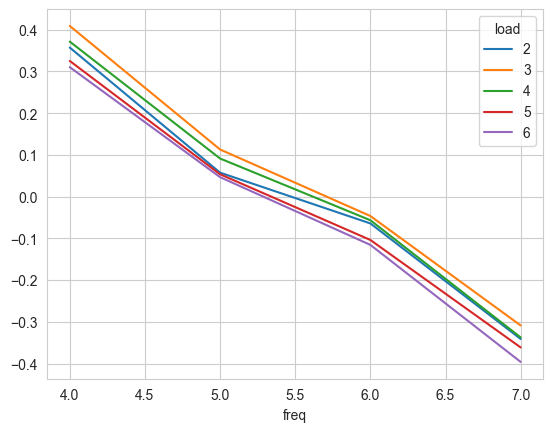

In [29]:
df_mean.pivot(index="freq", columns="load", values="psd_mean").plot()

In [30]:
sub = df_final[df_final["load"].isin([2, 3, 4, 5, 6])]

g = (
    sub
    .groupby(["participant", "freq", "load"])["psd_z_within"]
    .mean()
    .unstack("load")
)

loads = [2, 3, 4, 5, 6]

# freq mean -> table participant × load
g_part = (
    g.reset_index()              # participant, freq, 2,3,4,5,6
     .groupby("participant")[loads]
     .mean()
)

t_table = pd.DataFrame(index=loads, columns=loads, dtype=float)
p_table = pd.DataFrame(index=loads, columns=loads, dtype=float)

for a, b in itertools.combinations(loads, 2):
    d = g_part[[a, b]].dropna()

    if len(d) == 0:
        continue

    t, p = ttest_rel(d[a], d[b])

    t_table.loc[a, b] = t
    t_table.loc[b, a] = t
    p_table.loc[a, b] = p
    p_table.loc[b, a] = p

np.fill_diagonal(t_table.values, np.nan)
np.fill_diagonal(p_table.values, np.nan)

t_table

,2,3,4,5,6
2,NaN,-1.683671,-0.609300,1.100473,2.192560
3,-1.683671,NaN,1.049215,2.557681,3.607119
4,-0.609300,1.049215,NaN,2.169263,2.530507
5,1.100473,2.557681,2.169263,NaN,0.722521
6,2.192560,3.607119,2.530507,0.722521,NaN


In [31]:
p_table

,2,3,4,5,6
2,NaN,0.094442,0.543299,0.272988,0.029967
3,0.094442,NaN,0.295862,0.011586,0.000428
4,0.543299,0.295862,NaN,0.031727,0.012480
5,0.272988,0.011586,0.031727,NaN,0.471163
6,0.029967,0.000428,0.012480,0.471163,NaN


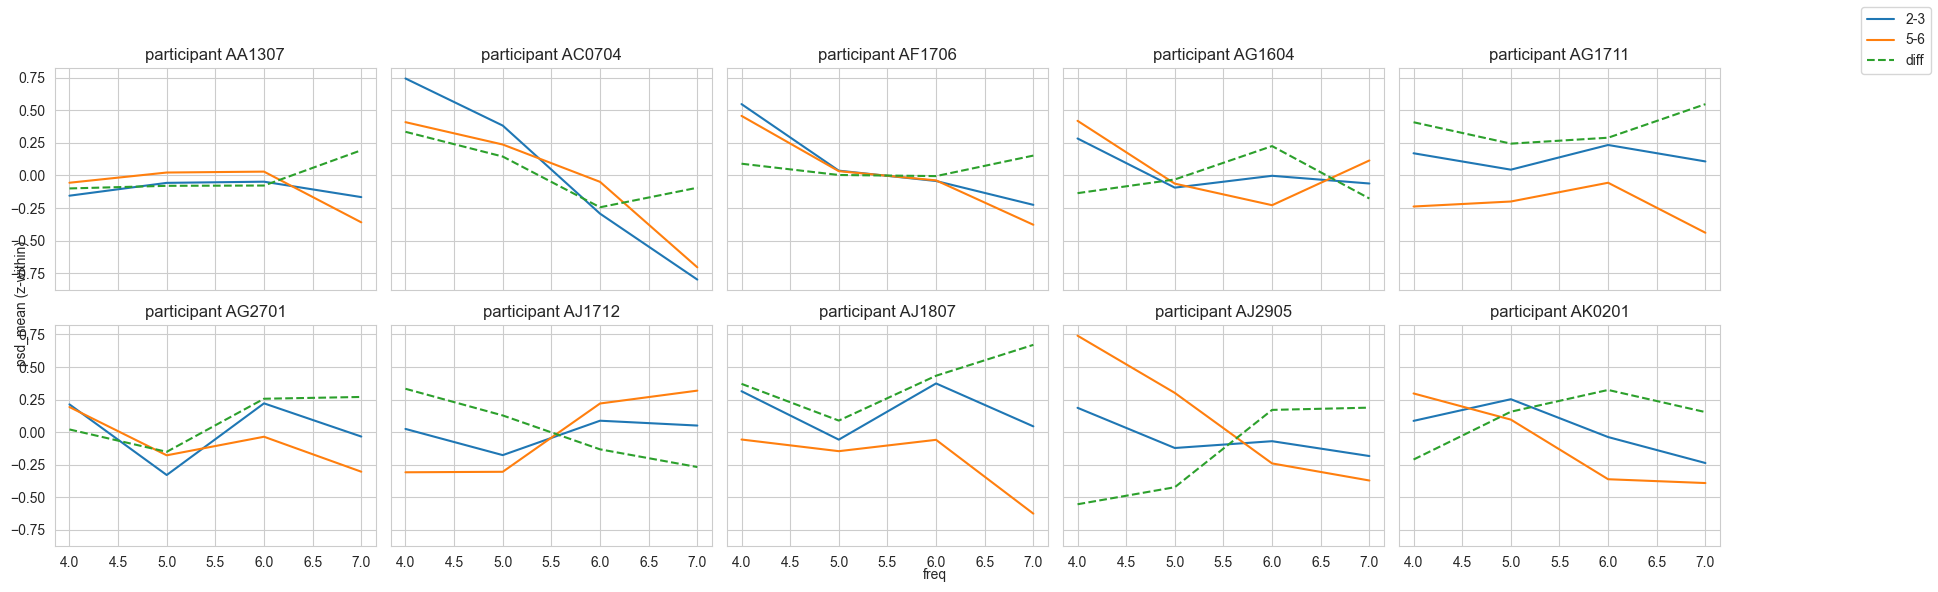

In [32]:
# --- Wykresy dla kilku uczestników ---

unique_parts = df_final["participant"].unique()
unique_parts = np.sort(unique_parts)   # sortowanie, żeby były w stałej kolejności

n_parts_to_plot = 10  # ilu uczestników chcesz narysować
parts_to_plot = unique_parts[:n_parts_to_plot]

n_cols = 5                    # ile kolumn subplota
n_rows = int(np.ceil(n_parts_to_plot / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 3*n_rows), sharex=True, sharey=True)
axes = axes.flatten()

for ax, part_id in zip(axes, parts_to_plot):
    df_mean_part = (
        df_final[df_final["participant"] == part_id]
        .groupby(["load", "freq"], as_index=False)["psd_z_within"]
        .mean()
        .rename(columns={"psd_z_within": "psd_mean"})
    )

    pivot_part = df_mean_part.pivot(index="freq", columns="load", values="psd_mean")

    # Sprawdź, czy mamy wymagane obciążenia
    required_loads = [2, 3, 5, 6]
    if not all(l in pivot_part.columns for l in required_loads):
        ax.set_title(f"{part_id} (brak części obciążeń)")
        ax.axis("off")
        continue

    plot_df_part = pd.DataFrame({
        "2-3": pivot_part[[2, 3]].mean(axis=1),
        "5-6": pivot_part[[5, 6]].mean(axis=1),
    })
    plot_df_part["diff"] = plot_df_part["2-3"] - plot_df_part["5-6"]

    ax.plot(plot_df_part.index, plot_df_part["2-3"], label="2-3")
    ax.plot(plot_df_part.index, plot_df_part["5-6"], label="5-6")
    ax.plot(plot_df_part.index, plot_df_part["diff"], label="diff", linestyle="--")

    ax.set_title(f"participant {part_id}")
    ax.grid(True)

# Schowaj puste osie, jeśli jest ich więcej niż uczestników
for ax in axes[len(parts_to_plot):]:
    ax.axis("off")

fig.text(0.5, 0.04, "freq", ha="center")
fig.text(0.04, 0.5, "psd_mean (z-within)", va="center", rotation="vertical")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right")
plt.tight_layout(rect=[0.03, 0.03, 0.9, 0.95])
plt.show()

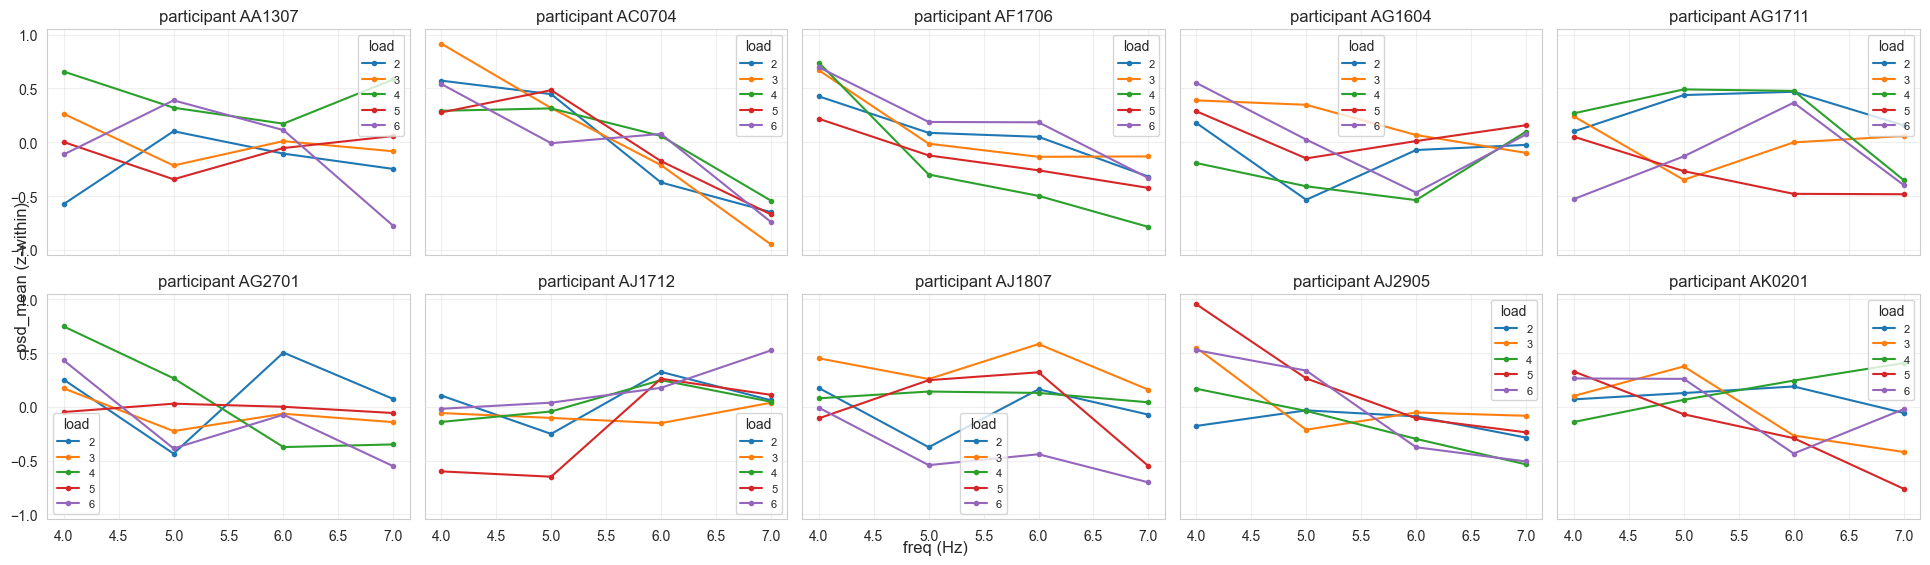

In [33]:
# --- Wykresy dla kilku uczestników z osobnymi liniami dla każdego load ---

unique_parts = df_final["participant"].unique()
unique_parts = np.sort(unique_parts)   # sortowanie, żeby były w stałej kolejności

n_parts_to_plot = 10  # ilu uczestników chcesz narysować
parts_to_plot = unique_parts[:n_parts_to_plot]

n_cols = 5                    # ile kolumn subplota
n_rows = int(np.ceil(n_parts_to_plot / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 3*n_rows), sharex=True, sharey=True)
axes = axes.flatten()

for ax, part_id in zip(axes, parts_to_plot):
    df_mean_part = (
        df_final[df_final["participant"] == part_id]
        .groupby(["load", "freq"], as_index=False)["psd_z_within"]
        .mean()
        .rename(columns={"psd_z_within": "psd_mean"})
    )

    pivot_part = df_mean_part.pivot(index="freq", columns="load", values="psd_mean")

    # Rysuj każdy load osobno
    pivot_part.plot(ax=ax, marker='o', markersize=3)

    ax.set_title(f"participant {part_id}")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(True, alpha=0.3)
    ax.legend(title="load", fontsize=8)

# Schowaj puste osie, jeśli jest ich więcej niż uczestników
for ax in axes[len(parts_to_plot):]:
    ax.axis("off")

fig.text(0.5, 0.04, "freq (Hz)", ha="center", fontsize=12)
fig.text(0.04, 0.5, "psd_mean (z-within)", va="center", rotation="vertical", fontsize=12)
plt.tight_layout(rect=[0.03, 0.03, 1, 0.97])
plt.show()

In [34]:
# TODO: MI dla każdego load
# TODO: policzyć IAF
# TODO: dla każdej osoby maksimum MI i próba korelacji z IAF